# Part 1 — Distribution
Analyze the dataset and display pie charts and bar charts for each plant type.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

from src.data import CLASSES, DATA_PATH, resolve_images

In [2]:
data = resolve_images(DATA_PATH, CLASSES)

In [3]:
a = ""

for i, k in data.items():
    a = k[0]
    break
a

'/home/samy/Leaffliction/data/leaves/images/Apple_Black_rot/image (456).JPG'

In [4]:
data.keys()

dict_keys(['Apple_Black_rot', 'Apple_healthy', 'Apple_rust', 'Apple_scab', 'Grape_Black_rot', 'Grape_Esca', 'Grape_healthy', 'Grape_spot'])

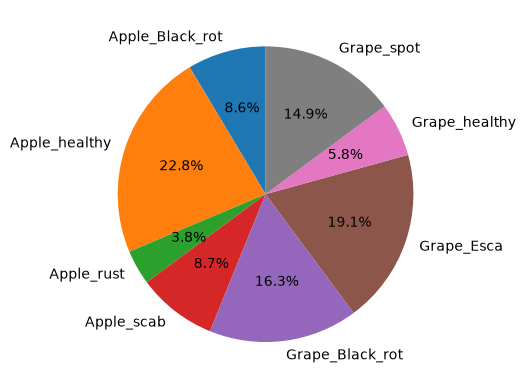

In [5]:
import matplotlib.pyplot as plt

plt.pie(
    [len(images) for images in data.values()],
    labels=list(data.keys()),
    autopct="%1.1f%%",
    startangle=90,
)

([<matplotlib.axis.XTick at 0x7f5a8e688350>,
 [Text(0, 0, 'Apple_Black_rot'),
  Text(1, 0, 'Apple_healthy'),
  Text(2, 0, 'Apple_rust'),
  Text(3, 0, 'Apple_scab'),
  Text(4, 0, 'Grape_Black_rot'),
  Text(5, 0, 'Grape_Esca'),
  Text(6, 0, 'Grape_healthy'),
  Text(7, 0, 'Grape_spot')])

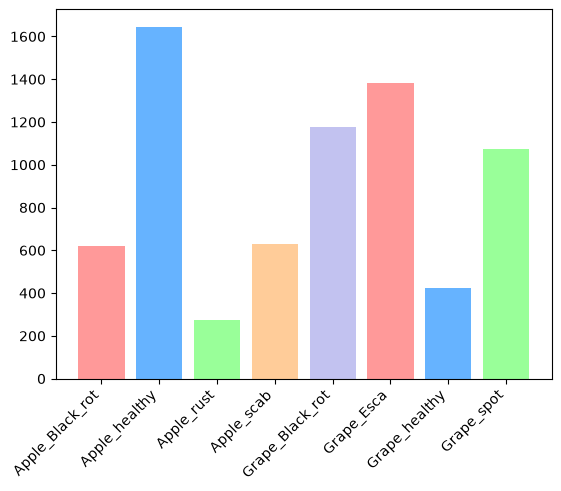

In [6]:
categories = list(data.keys())
my_colors = ["#ff9999", "#66b3ff", "#99ff99", "#ffcc99", "#c2c2f0"]

plt.bar(list(data.keys()), [len(images) for images in data.values()], color=my_colors)
plt.xticks(
    ticks=range(len(categories)),
    labels=categories,
    rotation=45,  # Rotates text to prevent overlapping
    ha="right",  # Aligns the right edge of text to the tick mark
    fontsize=10,
)

## Verification on augmented_directory
After Part 2 balances the dataset, re-run Distribution on `augmented_directory`.
Each slice of the pie chart must be equal.

In [7]:
augmented_dir = Path.cwd().parent / "augmented_directory"
assert augmented_dir.exists(), (
    f"augmented_directory not found at {augmented_dir}. "
    "Run 02_part.ipynb (Augmentation) first to generate it."
)

augmented_data = resolve_images(augmented_dir, CLASSES)
aug_counts = {k: len(v) for k, v in augmented_data.items()}
print("augmented_directory class counts:")
for c, n in aug_counts.items():
    print(f"  {c:20s}  {n}")
print(f"\nAll equal: {len(set(aug_counts.values())) == 1}")

augmented_directory class counts:
  Apple_Black_rot       1646
  Apple_healthy         1646
  Apple_rust            1646
  Apple_scab            1646
  Grape_Black_rot       1646
  Grape_Esca            1646
  Grape_healthy         1646
  Grape_spot            1646

All equal: True


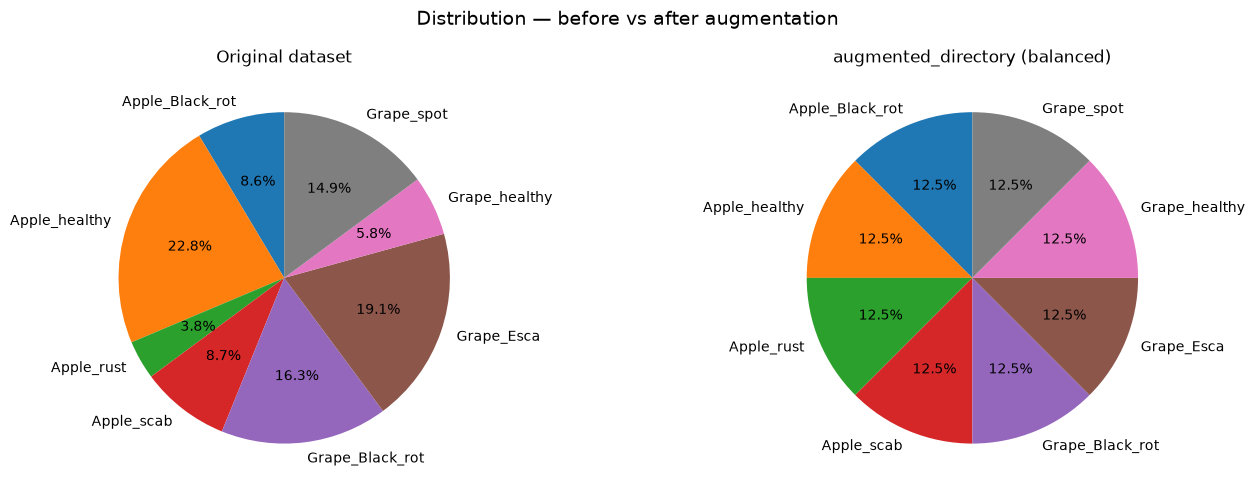

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].pie(
    [len(images) for images in data.values()],
    labels=list(data.keys()),
    autopct="%1.1f%%",
    startangle=90,
)
axes[0].set_title("Original dataset")

axes[1].pie(
    [len(images) for images in augmented_data.values()],
    labels=list(augmented_data.keys()),
    autopct="%1.1f%%",
    startangle=90,
)
axes[1].set_title("augmented_directory (balanced)")

plt.suptitle("Distribution — before vs after augmentation", fontsize=14)
plt.tight_layout()
plt.show()